In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from pathlib import Path
import math

sns.set_style("darkgrid")

DATASET_DIR = Path("../datasets")
PREFIX_LEN = 50  # suffix starts at index 50

# Style constants
LEVEL_COLORS = sns.color_palette("husl", 3)   # 3 levels: 0, 1, 2a
STRATEGY_COLORS = sns.color_palette("husl", 5)  # 5 strategies for 2a

SINGLE_FIG  = (10, 6)
WIDE_FIG    = (14, 6)
SUMMARY_FIG = (14, 8)

TITLE_SIZE  = 18
LABEL_SIZE  = 16
TICK_SIZE   = 14
LEGEND_SIZE = 13

In [2]:
def parse_filename(path: Path):
    """Parse NPZ filename to extract level, strategy, and seed.

    Expected format: level<X>_[strategy_]lookup[_params]_seed<N>.npz
    Examples:
      level0_lookup_seed0
      level1_lookup_pos2_seed0
      level2a_sin_lookup_seed0
      level2a_polynomial_prime_lookup_polynomial_degree3_prime_modulus1009_seed0
    """
    stem = path.stem
    parts = stem.split("_")

    # --- level ---
    # parts[0] is always "level<X>" e.g. "level0", "level1", "level2a"
    if not parts[0].startswith("level"):
        raise ValueError(f"Expected first part to start with 'level', got: {parts[0]!r}")
    level = parts[0][len("level"):]  # '0', '1', '2a'

    # --- seed ---
    # parts[-1] is always "seed<N>" e.g. "seed0"
    if not parts[-1].startswith("seed"):
        raise ValueError(f"Expected last part to start with 'seed', got: {parts[-1]!r}")
    seed = int(parts[-1][len("seed"):])

    # --- strategy ---
    # Parts between parts[0] and "lookup" (exclusive) form the strategy name.
    if "lookup" in parts:
        lookup_idx = parts.index("lookup")
        strategy_parts = parts[1:lookup_idx]
        strategy = "_".join(strategy_parts) if strategy_parts else None
    else:
        strategy = None

    return level, strategy, seed


def load_datasets():
    """Scan DATASET_DIR, load all NPZ files, return list of dicts."""
    records = []
    for npz_path in sorted(DATASET_DIR.glob("*.npz")):
        try:
            level, strategy, seed = parse_filename(npz_path)
        except (ValueError, IndexError) as e:
            print(f"Skipping {npz_path.name}: {e}")
            continue

        data = np.load(npz_path, allow_pickle=True)
        dataset = data["dataset"]          # (N, 100) int64
        metadata = data["metadata"].item() if "metadata" in data else {}

        suffix = dataset[:, PREFIX_LEN:]   # (N, 50) – eval window
        prefix = dataset[:, :PREFIX_LEN]   # (N, 50) – prefix window

        records.append({
            "level":    level,
            "strategy": strategy,
            "seed":     seed,
            "suffix":   suffix,
            "prefix":   prefix,
            "metadata": metadata,
        })

    print(f"Loaded {len(records)} datasets")
    for r in records:
        print(f"  level={r['level']:3s}  strategy={str(r['strategy']):25s}  seed={r['seed']}  suffix shape={r['suffix'].shape}")
    return records


records = load_datasets()

Loaded 21 datasets
  level=0    strategy=None                       seed=0  suffix shape=(6000, 50)
  level=0    strategy=None                       seed=1  suffix shape=(6000, 50)
  level=0    strategy=None                       seed=2  suffix shape=(6000, 50)
  level=1    strategy=None                       seed=0  suffix shape=(6000, 50)
  level=1    strategy=None                       seed=1  suffix shape=(6000, 50)
  level=1    strategy=None                       seed=2  suffix shape=(6000, 50)
  level=2a   strategy=lookback                   seed=0  suffix shape=(6000, 50)
  level=2a   strategy=lookback                   seed=1  suffix shape=(6000, 50)
  level=2a   strategy=lookback                   seed=2  suffix shape=(6000, 50)
  level=2a   strategy=modulo                     seed=0  suffix shape=(6000, 50)
  level=2a   strategy=modulo                     seed=1  suffix shape=(6000, 50)
  level=2a   strategy=modulo                     seed=2  suffix shape=(6000, 50)
  level=2

In [3]:
def compute_ngram_stats(sequences: np.ndarray, n: int) -> dict:
    """
    Compute n-gram statistics over a (N, L) array of token sequences.

    Returns a dict with:
      entropy            – joint n-gram entropy H(t1,...,tn) in bits
      unique_count       – number of distinct n-grams observed
      ttr                – type-token ratio  = unique_count / total_ngrams
      top5_concentration – fraction of token occurrences covered by top-5 n-grams
    """
    N, L = sequences.shape
    counter = Counter()

    for seq in sequences:
        for i in range(L - n + 1):
            gram = tuple(seq[i : i + n])
            counter[gram] += 1

    total = sum(counter.values())
    if total == 0:
        return {"entropy": 0.0, "unique_count": 0, "ttr": 0.0, "top5_concentration": 0.0}

    # Entropy
    entropy = 0.0
    for cnt in counter.values():
        p = cnt / total
        entropy -= p * math.log2(p)

    # TTR
    unique_count = len(counter)
    ttr = unique_count / total

    # Top-5 concentration
    top5 = sum(cnt for _, cnt in counter.most_common(5))
    top5_concentration = top5 / total

    return {
        "entropy":           entropy,
        "unique_count":      unique_count,
        "ttr":               ttr,
        "top5_concentration": top5_concentration,
    }

In [4]:
rows_suffix = []
rows_prefix = []

for rec in records:
    for n in [1, 2, 3]:
        stats_suf = compute_ngram_stats(rec["suffix"], n)
        rows_suffix.append({
            "level":    rec["level"],
            "strategy": rec["strategy"] if rec["strategy"] else "–",
            "seed":     rec["seed"],
            "n":        n,
            **stats_suf,
        })

        stats_pre = compute_ngram_stats(rec["prefix"], n)
        rows_prefix.append({
            "level":    rec["level"],
            "strategy": rec["strategy"] if rec["strategy"] else "–",
            "seed":     rec["seed"],
            "n":        n,
            **stats_pre,
        })

df_suffix = pd.DataFrame(rows_suffix)
df_prefix = pd.DataFrame(rows_prefix)

print("Suffix stats shape:", df_suffix.shape)
df_suffix.head(9)

Suffix stats shape: (63, 8)


,level,strategy,seed,n,entropy,unique_count,ttr,top5_concentration
0,0,–,0,1,6.643651,100,0.000333,0.052063
1,0,–,0,2,11.793989,3842,0.013068,0.004327
2,0,–,0,3,12.210717,4785,0.016615,0.002281
3,0,–,1,1,6.643703,100,0.000333,0.051303
4,0,–,1,2,11.808222,3884,0.013211,0.004660
5,0,–,1,3,12.210755,4779,0.016594,0.002451
6,0,–,2,1,6.643682,100,0.000333,0.051500
7,0,–,2,2,11.821445,3906,0.013286,0.004592
8,0,–,2,3,12.217644,4795,0.016649,0.002135


In [5]:
def aggregate(df):
    """Mean ± std across seeds, grouped by (level, strategy, n)."""
    grp = df.groupby(["level", "strategy", "n"])
    mean = grp[["entropy", "unique_count", "ttr", "top5_concentration"]].mean()
    std  = grp[["entropy", "unique_count", "ttr", "top5_concentration"]].std().fillna(0)
    std.columns = [c + "_std" for c in std.columns]
    return pd.concat([mean, std], axis=1).reset_index()


agg_suffix = aggregate(df_suffix)
agg_prefix = aggregate(df_prefix)

# Build a per-level aggregate (collapsing strategies within 2a)
def aggregate_by_level(df):
    grp = df.groupby(["level", "n"])
    mean = grp[["entropy", "unique_count", "ttr", "top5_concentration"]].mean()
    std  = grp[["entropy", "unique_count", "ttr", "top5_concentration"]].std().fillna(0)
    std.columns = [c + "_std" for c in std.columns]
    return pd.concat([mean, std], axis=1).reset_index()


agg_lvl_suffix = aggregate_by_level(df_suffix)
agg_lvl_prefix = aggregate_by_level(df_prefix)

print(agg_lvl_suffix)

  level  n    entropy   unique_count       ttr  top5_concentration  \
0     0  1   6.643679     100.000000  0.000333            0.051622   
1     0  2  11.807885    3877.333333  0.013188            0.004526   
2     0  3  12.213039    4786.333333  0.016619            0.002289   
3     1  1   6.640376     100.000000  0.000333            0.057288   
4     1  2  12.954321    9925.666667  0.033761            0.002367   
5     1  3  14.819852   46657.666667  0.162006            0.001047   
6    2a  1   6.643498     100.000000  0.000333            0.052166   
7    2a  2  13.248172   10000.000000  0.034014            0.000974   
8    2a  3  17.843442  247670.333333  0.859966            0.000096   

   entropy_std  unique_count_std   ttr_std  top5_concentration_std  
0     0.000026          0.000000  0.000000                0.000394  
1     0.013731         32.516662  0.000111                0.000176  
2     0.003988          8.082904  0.000028                0.000158  
3     0.000445         

In [6]:
level_order = ["0", "1", "2a"]
level_map   = {"0": "Level 0", "1": "Level 1", "2a": "Level 2a"}

### Figure 2 — N-gram Entropy by Conditioning Level

**How it is computed.** All n-grams of length *n* are extracted from the 50-token suffix window of every sequence. The entropy is H = −Σ p(gram) log₂ p(gram), where p(gram) is the empirical frequency of each distinct n-gram pooled over all 3,000 sequences in the dataset. Higher entropy means the n-gram distribution is more uniform and therefore harder to predict. The theoretical maximum for unigrams over a 100-token vocabulary is log₂(100) ≈ 6.64 bits. Error bars show ±1 std across seeds.

**What it shows.** All three levels share nearly identical *unigram* entropy (≈ 6.64 bits), confirming that the marginal token distribution is uniform in every dataset. The levels diverge as n grows: Level 0's entropy barely increases beyond bigrams (≈ 12.2 bits at trigrams), while Level 2a reaches ≈ 16.5 bits — indicating far richer higher-order sequential dependencies.

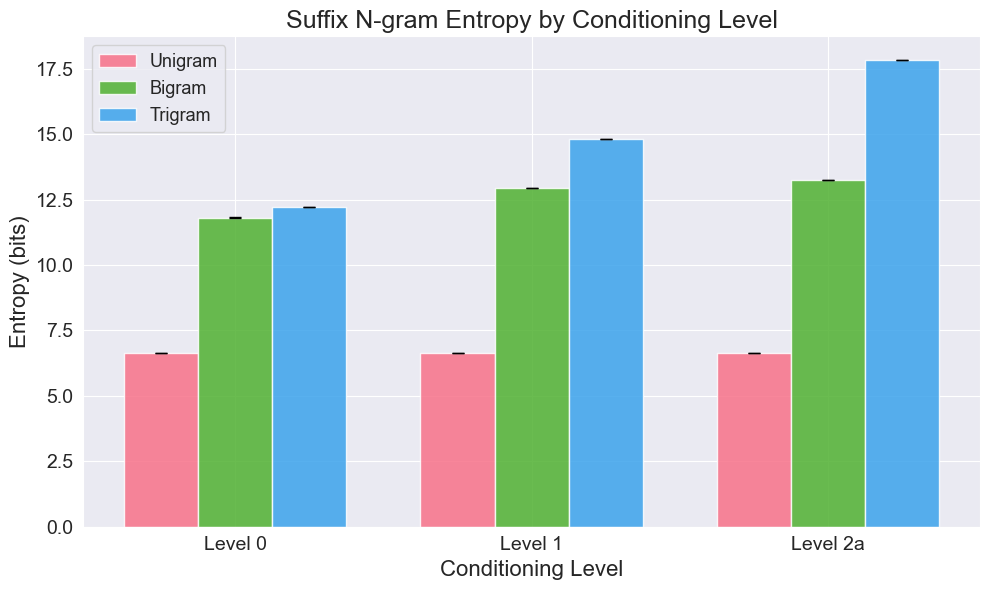

In [7]:
# ── Figure 2 ── Entropy Comparison Across Levels ───────────────────────────────

ngram_labels = {1: "Unigram", 2: "Bigram", 3: "Trigram"}
ngram_colors = sns.color_palette("husl", 3)

fig, ax = plt.subplots(figsize=SINGLE_FIG)

n_levels  = len(level_order)
n_ngrams  = 3
bar_width = 0.25
x = np.arange(n_levels)

for i, n in enumerate([1, 2, 3]):
    sub = agg_lvl_suffix[agg_lvl_suffix["n"] == n].set_index("level")
    means = [sub.loc[lvl, "entropy"]     for lvl in level_order]
    stds  = [sub.loc[lvl, "entropy_std"] for lvl in level_order]
    offset = (i - 1) * bar_width
    ax.bar(x + offset, means, bar_width, label=ngram_labels[n],
           color=ngram_colors[i], alpha=0.85,
           yerr=stds, capsize=4, error_kw={"linewidth": 1.2})

ax.set_xticks(x)
ax.set_xticklabels([level_map[lvl] for lvl in level_order], fontsize=TICK_SIZE)
ax.set_ylabel("Entropy (bits)", fontsize=LABEL_SIZE)
ax.set_xlabel("Conditioning Level", fontsize=LABEL_SIZE)
ax.set_title("Suffix N-gram Entropy by Conditioning Level", fontsize=TITLE_SIZE)
ax.legend(fontsize=LEGEND_SIZE)
ax.tick_params(labelsize=TICK_SIZE)

plt.tight_layout()
plt.savefig("plots/dataset-stats-fig2-entropy.pdf", bbox_inches="tight")
plt.show()

### Figure 4 — Type-Token Ratio (TTR) by Conditioning Level

**How it is computed.** TTR = (number of distinct n-grams observed) / (total n-gram tokens). For unigrams with a 100-token vocabulary and 3,000 × 50 = 150,000 token positions, TTR = 100 / 150,000 ≈ 0.00067. TTR approaches 0 when sequences are highly repetitive; it approaches 1 when almost every n-gram position holds a unique pattern.

**What it shows.** Unigram TTR is identical across all levels (all 100 tokens appear but each is repeated ~1,500 times). The dramatic split appears at trigrams: Level 2a reaches TTR ≈ 0.78 (78 % of all trigram positions are unique), compared to only ≈ 3.3 % for Level 0. This directly quantifies the memorization challenge — in Level 2a the model encounters almost no repeated trigram pattern, while Level 0 is built from a small, heavily reused set of triples.

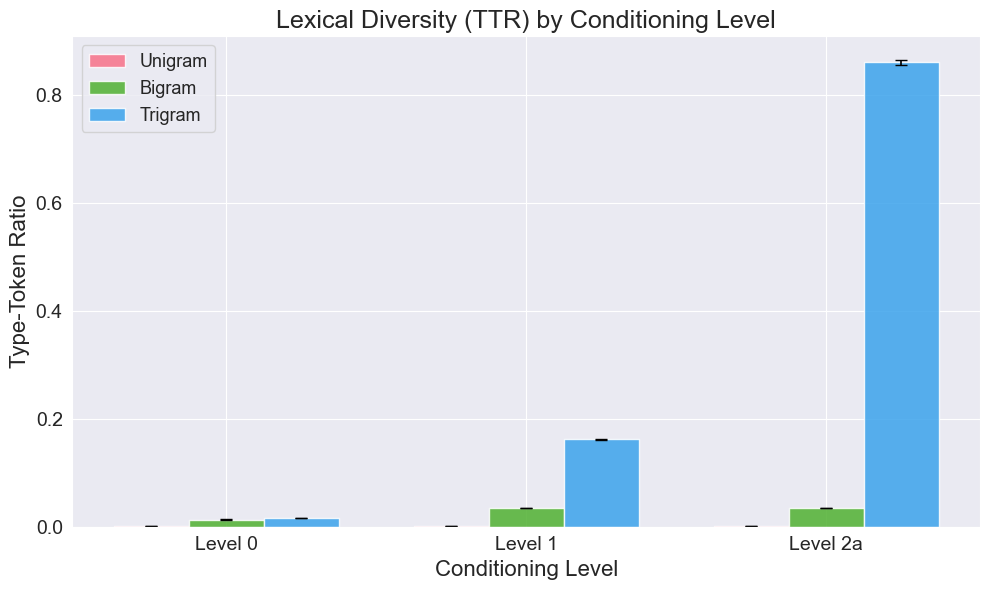

In [8]:
# ── Figure 4 ── Type-Token Ratio ───────────────────────────────────────────────

fig, ax = plt.subplots(figsize=SINGLE_FIG)

for i, n in enumerate([1, 2, 3]):
    sub = agg_lvl_suffix[agg_lvl_suffix["n"] == n].set_index("level")
    means = [sub.loc[lvl, "ttr"]     for lvl in level_order]
    stds  = [sub.loc[lvl, "ttr_std"] for lvl in level_order]
    offset = (i - 1) * bar_width
    ax.bar(x + offset, means, bar_width, label=ngram_labels[n],
           color=ngram_colors[i], alpha=0.85,
           yerr=stds, capsize=4, error_kw={"linewidth": 1.2})

ax.set_xticks(x)
ax.set_xticklabels([level_map[lvl] for lvl in level_order], fontsize=TICK_SIZE)
ax.set_ylabel("Type-Token Ratio", fontsize=LABEL_SIZE)
ax.set_xlabel("Conditioning Level", fontsize=LABEL_SIZE)
ax.set_title("Lexical Diversity (TTR) by Conditioning Level", fontsize=TITLE_SIZE)
ax.legend(fontsize=LEGEND_SIZE)
ax.tick_params(labelsize=TICK_SIZE)

plt.tight_layout()
plt.savefig("plots/dataset-stats-fig4-ttr.pdf", bbox_inches="tight")
plt.show()